In [3]:
import gym
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical

In [17]:
import random
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [18]:
class ActorCritic(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_size=512):
        super(ActorCritic, self).__init__()
        # Shared layer
        self.fc = nn.Linear(state_dim, hidden_size)
        
        # Policy (actor) head
        self.policy = nn.Linear(hidden_size, action_dim)
        
        # Value (critic) head
        self.value = nn.Linear(hidden_size, 1)

    def forward(self, x):
        x = torch.tanh(self.fc(x))
        policy_logits = self.policy(x)
        value = self.value(x)
        return policy_logits, value

In [19]:
def compute_returns_and_advantages(rewards, values, dones, gamma, lam):
    advantages = []
    gae = 0
    values = values + [0]  # Add a dummy for bootstrap
    
    for t in reversed(range(len(rewards))):
        delta = rewards[t] + gamma * values[t+1] * (1 - dones[t]) - values[t]
        gae = delta + gamma * lam * (1 - dones[t]) * gae
        advantages.insert(0, gae)
    returns = [adv + val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns


In [20]:
def ppo_minibatch_update(model, optimizer, states, actions, log_probs_old, returns, advantages, clip_eps, epochs, mini_batch_size=256):
    dataset_size = len(states)
    indices = np.arange(dataset_size)

    states = torch.tensor(states, dtype=torch.float32)
    actions = torch.tensor(actions, dtype=torch.int64)
    log_probs_old = torch.tensor(log_probs_old, dtype=torch.float32)
    returns = torch.tensor(returns, dtype=torch.float32)
    advantages = torch.tensor(advantages, dtype=torch.float32)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    for _ in range(epochs):
        np.random.shuffle(indices)
        for start in range(0, dataset_size, mini_batch_size):
            end = start + mini_batch_size
            minib_idx = indices[start:end]
            minib_states = states[minib_idx]
            minib_actions = actions[minib_idx]
            minib_old_log_probs = log_probs_old[minib_idx]
            minib_returns = returns[minib_idx]
            minib_advantages = advantages[minib_idx]

            logits, values = model(minib_states)
            dist = Categorical(logits=logits)
            log_probs_new = dist.log_prob(minib_actions)
            ratio = torch.exp(log_probs_new - minib_old_log_probs)

            clipped = torch.clamp(ratio, 1 - clip_eps, 1 + clip_eps) * minib_advantages
            actor_loss = -torch.min(ratio * minib_advantages, clipped).mean()

    # Critic loss (MSE)
            critic_loss = nn.MSELoss()(values.squeeze(), minib_returns)

    # Total loss
    # loss = actor_loss + 0.5 * critic_loss
            entropy = dist.entropy().mean()
            loss = actor_loss + 0.5 * critic_loss - 0.01 * entropy

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()


In [21]:


# Train function returning rewards
def train_ppo(model, optimizer, env, max_env_steps, batch_size, gamma, lambda_, clip_eps, epochs=4, mini_batch_size=256):
    reward_per_episode = []
    env_steps = []
    step_counter = 0
    state, _ = env.reset()

    while step_counter < max_env_steps:
        states, actions, rewards, dones, log_probs, values = [], [], [], [], [], []
        batch_steps = 0

        while batch_steps < batch_size:
            episode_reward = 0
            done=False

            while not done:
                state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
                logits, value = model(state_tensor)
                dist = Categorical(logits=logits)
                action = dist.sample()

                next_state, reward, terminated, truncated, _ = env.step(action.item())
                done = terminated or truncated

                states.append(state)
                actions.append(action.item())
                rewards.append(reward)
                dones.append(done)
                log_probs.append(dist.log_prob(action).item())
                values.append(value.item())

                state = next_state
                step_counter +=1
                batch_steps +=1
                episode_reward += reward

                if done or step_counter >= max_env_steps:
                    reward_per_episode.append(episode_reward)
                    env_steps.append(step_counter)
                    state, _ = env.reset()
                    break

            if step_counter >= max_env_steps:
                break

        advantages, returns = compute_returns_and_advantages(rewards, values, dones, gamma, lambda_)
        ppo_minibatch_update(model, optimizer, states, actions, log_probs, returns, advantages, clip_eps, epochs, mini_batch_size)

        print(f"Step {step_counter}/{max_env_steps} | Avg Reward (last 10): {np.mean(reward_per_episode[-10:]):.2f}")

    env.close()

    return reward_per_episode, env_steps


In [22]:

config = {
    'learning_rate': 1e-3,
    'batch_size': 3000,
    'gamma': 0.99,
    'lambda': 0.95,
    'clip_eps': 0.4
}


MAX_ENV_STEPS = 100000
REPEATS = 5
results = []

for rep in range(REPEATS):
    print(f"\n=== Run {rep+1}/{REPEATS} ===")
    seed = 42 + rep
    set_seed(seed)

    env = gym.make("CartPole-v1")
    env.reset(seed=seed)

    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.n

    model = ActorCritic(state_dim, action_dim)
    optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])

    episode_return, env_step = train_ppo(
        model=model,
        optimizer=optimizer,
        env=env,
        max_env_steps=MAX_ENV_STEPS,
        batch_size=config['batch_size'],
        gamma=config['gamma'],
        lambda_=config['lambda'],
        clip_eps=config['clip_eps'],
        epochs = 4,
        mini_batch_size=256
    )

    results.append((episode_return, env_step))


=== Run 1/5 ===
Step 3036/100000 | Avg Reward (last 10): 24.40
Step 6068/100000 | Avg Reward (last 10): 31.30
Step 9076/100000 | Avg Reward (last 10): 68.20
Step 12115/100000 | Avg Reward (last 10): 165.60
Step 15329/100000 | Avg Reward (last 10): 155.00
Step 18374/100000 | Avg Reward (last 10): 80.30
Step 21489/100000 | Avg Reward (last 10): 228.40
Step 24505/100000 | Avg Reward (last 10): 208.10
Step 27745/100000 | Avg Reward (last 10): 269.80
Step 31106/100000 | Avg Reward (last 10): 336.10
Step 34252/100000 | Avg Reward (last 10): 206.30
Step 37364/100000 | Avg Reward (last 10): 191.50
Step 40618/100000 | Avg Reward (last 10): 280.70
Step 43618/100000 | Avg Reward (last 10): 300.00
Step 46872/100000 | Avg Reward (last 10): 325.40
Step 49879/100000 | Avg Reward (last 10): 350.20
Step 53167/100000 | Avg Reward (last 10): 367.90
Step 56605/100000 | Avg Reward (last 10): 418.60
Step 59727/100000 | Avg Reward (last 10): 201.70
Step 62938/100000 | Avg Reward (last 10): 356.30
Step 66260

c:\reinforcement learning\RL_A3\.venv\lib\site-packages\torch\nn\modules\loss.py:536: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Step 56398/100000 | Avg Reward (last 10): 147.40
Step 59474/100000 | Avg Reward (last 10): 180.50
Step 62663/100000 | Avg Reward (last 10): 288.50
Step 65692/100000 | Avg Reward (last 10): 161.10
Step 68719/100000 | Avg Reward (last 10): 210.20
Step 71966/100000 | Avg Reward (last 10): 277.20
Step 75161/100000 | Avg Reward (last 10): 205.40
Step 78442/100000 | Avg Reward (last 10): 388.40
Step 81829/100000 | Avg Reward (last 10): 471.80
Step 85165/100000 | Avg Reward (last 10): 483.60
Step 88165/100000 | Avg Reward (last 10): 487.90
Step 91308/100000 | Avg Reward (last 10): 464.30
Step 94320/100000 | Avg Reward (last 10): 426.80
Step 97320/100000 | Avg Reward (last 10): 456.40
Step 100000/100000 | Avg Reward (last 10): 468.00

=== Run 5/5 ===
Step 3032/100000 | Avg Reward (last 10): 23.20
Step 6041/100000 | Avg Reward (last 10): 49.60
Step 9067/100000 | Avg Reward (last 10): 110.00
Step 12158/100000 | Avg Reward (last 10): 192.10
Step 15231/100000 | Avg Reward (last 10): 209.90
Step 18

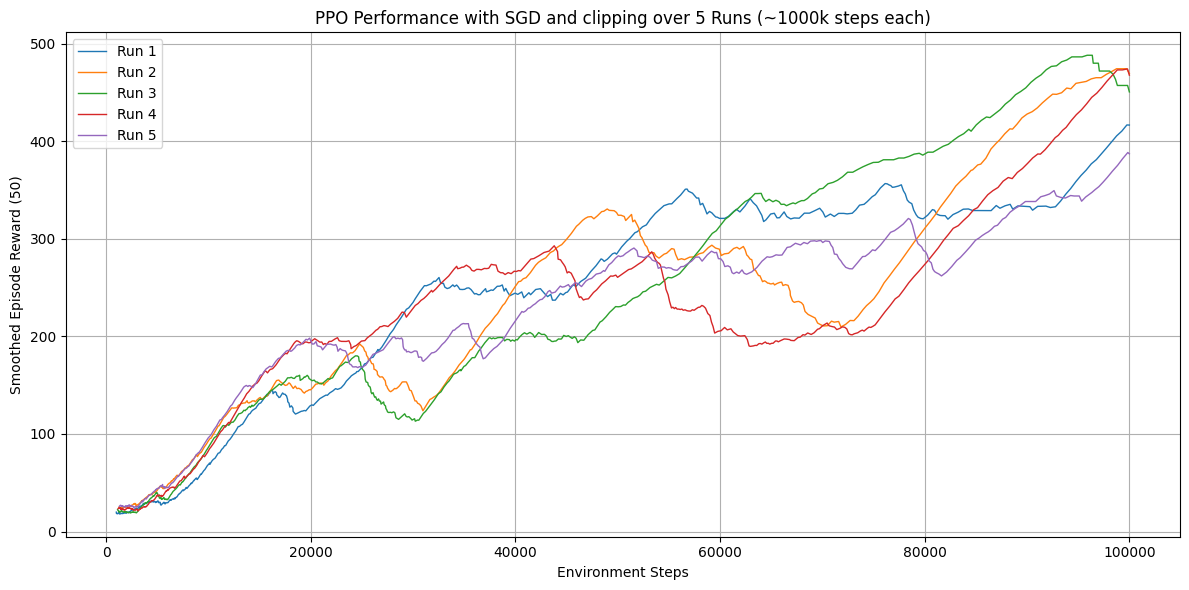

In [24]:
import matplotlib.pyplot as plt
window_size = 50
plt.figure(figsize=(12, 6))

for i, (episode_return, env_step) in enumerate(results):
    episode_return_smooth = np.convolve(episode_return, np.ones(window_size)/window_size, mode='valid')
    env_step_aligned = env_step[window_size - 1:]
    plt.plot(env_step_aligned, episode_return_smooth, label=f'Run {i+1}', linewidth=1)

plt.xlabel('Environment Steps')
plt.ylabel('Smoothed Episode Reward (50)')
plt.title('PPO Performance with SGD and clipping over 5 Runs (~1000k steps each)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
